# Quantamental Investing and AI: TSX Portfolio Strategies

Ten-stock TSX universe (CNQ, ENB, CCO, TD, BN, SHOP, TIH, ABX, L, CAE). One shared backtest: estimation Jun 2016-Dec 2021, test Jan 2022-Oct 2026, long only, 20% cap per stock, 40% cap per sector, 10 bps cost per trade.

This notebook reproduces the static and dynamic results. The LSTM is trained in `scripts/lstm_model.py` (TensorFlow) and its saved results are loaded here.

In [1]:
import sys, json
sys.path.insert(0, 'scripts')
import pandas as pd, numpy as np
from engine import SHORT, load_weekly, cap_weights, backtest, metrics
px, rets, bench, vix = load_weekly('.')
train = rets[rets.index < '2022-01-01']
test = rets[rets.index >= '2022-01-01']
print('train weeks:', len(train), '| test weeks:', len(test))
print('stocks:', SHORT)

train weeks: 291 | test weeks: 251
stocks: ['CNQ', 'ENB', 'CCO', 'TD', 'BN', 'SHOP', 'TIH', 'ABX', 'L', 'CAE']


## Static weights (estimated on the train window)

In [2]:
w = pd.read_csv('data/static_weights.csv', index_col=0)
display((w * 100).round(1))

,CNQ,ENB,CCO,TD,BN,SHOP,TIH,ABX,L,CAE
Equal Weight,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0
Max Sharpe,0.0,8.5,3.6,20.0,4.5,17.0,20.0,6.4,20.0,0.0
Min Variance,0.0,19.7,1.6,20.0,2.5,2.7,20.0,13.6,20.0,0.0
Risk Parity,5.8,11.6,7.1,13.4,7.9,7.2,12.7,11.3,16.5,6.7
CAPM Inverse-Beta,4.7,10.4,8.3,10.9,6.9,6.8,11.6,14.6,20.0,5.8
Fama-French 5,0.5,1.0,10.1,13.7,8.0,20.0,20.0,6.8,20.0,0.0


## Master results, test window, net of costs

In [3]:
import json
with open('data/static_results.json') as f: sr = json.load(f)['results']
with open('data/dynamic_results.json') as f: dr = json.load(f)
with open('data/lstm_results.json') as f: lr = json.load(f)
allres = {**sr, **dr, 'LSTM': lr['metrics']}
rows = []
for n, m in allres.items():
    rows.append({'Strategy': n, 'Ann return': round(m['ann_return']*100, 1),
                 'Ann vol': round(m['ann_vol']*100, 1), 'Sharpe': round(m['sharpe'], 2),
                 'Max DD': round(m['max_drawdown']*100, 1),
                 'CVaR95/wk': round(m['cvar95_weekly']*100, 2)})
display(pd.DataFrame(rows).sort_values('Sharpe', ascending=False))

,Strategy,Ann return,Ann vol,Sharpe,Max DD,CVaR95/wk
2,Min Variance,20.2,13.0,1.40,-16.7,-3.55
9,Regime-Aware CVaR,19.2,13.0,1.33,-17.8,-3.57
4,CAPM Inverse-Beta,22.3,15.2,1.33,-19.5,-4.20
3,Risk Parity,21.4,15.1,1.29,-19.1,-4.24
7,MACD Gate,20.4,14.5,1.27,-20.2,-3.79
0,Equal Weight,21.7,17.2,1.15,-20.7,-4.93
1,Max Sharpe,21.0,17.7,1.07,-21.9,-4.66
8,HMM Regime Gate,19.4,17.1,1.02,-22.3,-4.30
5,Fama-French 5,22.4,20.7,0.99,-24.7,-5.50
6,S&P/TSX Benchmark,11.4,12.9,0.73,-16.7,-4.04


## LSTM forecast check: does it beat the naive baseline?

In [4]:
print('MSE table:', lr['mse'])
print('LSTM epochs (early stopping):', lr['epochs'], '| val loss:', round(lr['val_loss'], 4))
print('LSTM yearly test returns:', {k: round(v['ann_return']*100, 1) for k, v in lr['yearly'].items()})

MSE table: {'LSTM test MSE': 0.0004922454369210356, 'Ridge test MSE': 0.0004909248813353098, 'Naive mean test MSE': 0.00048794573556952867, 'LSTM val MSE': 0.0003905882544467842}
LSTM epochs (early stopping): 12 | val loss: 0.7412
LSTM yearly test returns: {'2022': -13.0, '2023': 23.5, '2024': 8.4, '2025': 54.1, '2026': 0.2}


## Growth charts

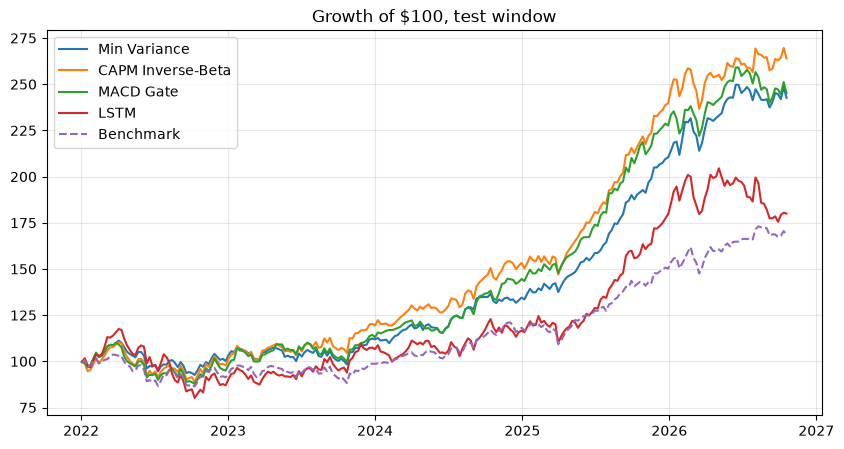

In [5]:
import matplotlib.pyplot as plt
sg = pd.read_csv('data/static_growth.csv', index_col=0, parse_dates=True)
dg = pd.read_csv('data/dynamic_growth.csv', index_col=0, parse_dates=True)
lg = pd.read_csv('data/lstm_growth.csv', index_col=0, parse_dates=True)
fig, ax = plt.subplots(figsize=(10, 5))
for c in ['Min Variance', 'CAPM Inverse-Beta', 'MACD Gate']:
    s = sg[c] if c in sg else dg[c]
    ax.plot(s.index, s, label=c)
ax.plot(lg.index, lg['LSTM'], label='LSTM')
ax.plot(sg.index, sg['S&P/TSX Benchmark'], label='Benchmark', ls='--')
ax.set_title('Growth of $100, test window'); ax.legend(); ax.grid(alpha=0.3)
plt.show()